# Captum tour: the data and the two models

**Goal**: use Captum to find the parts of a model that have **not converged** or **need more capacity**.

The test bed has a known answer: **16 features** with known roles, and **two separate models**, trained on the same
data, that differ only in their middle layer `fc2`:

```python
narrow = Student(width=3)    # fc2 has 3 units: deliberately too few (the "broken" model)
wide   = Student(width=64)   # fc2 has 64 units: the healthy control
```

Most plots show both models side by side. A tool works if it flags `fc2` in **narrow** and nothing in **wide**.

Every plot uses one of two frames: the **16 features** (same x-axis everywhere) or the **layers and units** of the
models (same names and colours everywhere). Each section starts with **pseudo-code** of what its code cells do, so
the code cells themselves can be skipped.

Files, in order (each runs on its own; `toy.py` holds the shared setup):

| File | § | Captum |
|---|---|---|
| `01_data_and_models` | 1–3 | (data, the two models, training) |
| `02_feature_attribution` | 4–11 | `attr` primary methods, `NoiseTunnel`, `ClassSummarizer`, `DataLoaderAttribution`, `metrics` |
| `03_model_attribution` | 12–16 | `attr` layer and neuron methods |
| `04_training_examples` | 17–20 | `influence` |
| `05_capacity_probes` | 21–23 | `module`, `concept`, `robust` |
| `06_expressivity_bottleneck` | 24 | none: plain PyTorch (`expressivity.py`) |
| `07_verdict` | 25–27 | all of the above |
| `08_digits_bottleneck` | | `expressivity.py` on another dataset and model |

**Run**: `pip install torch captum matplotlib pandas scikit-learn`. Open any file as a notebook (VS Code, PyCharm, or
Jupyter with jupytext), run it with `python`, or run `python run_all.py` to execute all of them and save `.ipynb`
copies with their outputs. Tested with torch 2.14 and captum 0.9.0.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

## 1. The 16 input features

| group | features | role |
|---|---|---|
| signal | `s0`–`s7` | the label depends on them; `s0` matters most, `s7` least |
| copies | `c0`–`c3` | noisy copies of `s0`–`s3` (correlation 0.9); the label does not use them |
| noise | `n0`–`n3` | pure noise |

```python
s = randn(N, 8);  n = randn(N, 4)
c = 0.9 * s[:, :4] + 0.44 * randn(N, 4)     # noisy copies of s0..s3
x = [s, c, n]                               # (N, 16)
y = argmax(teacher(s))                      # 10 balanced classes; the hidden teacher only sees s0..s7

for j in range(16):                         # ground truth importance
    truth[j] = share of labels that change when column j of x is shuffled
```

examples per class: [819, 772, 844, 809, 762, 748, 799, 778, 852, 817]


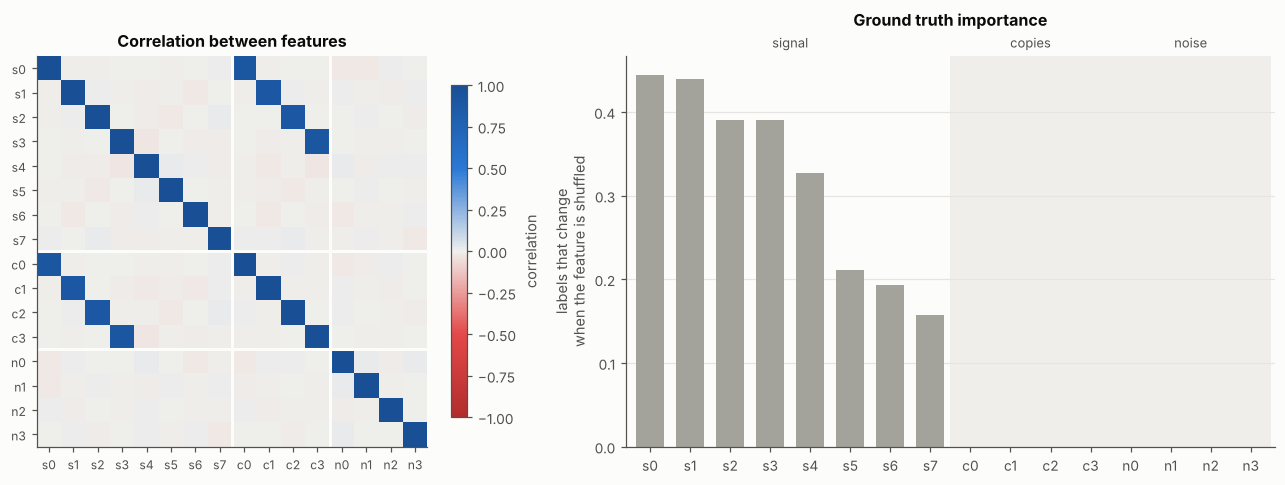

In [2]:
print("examples per class:", torch.bincount(Y).tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax = axes[0]
im = ax.imshow(np.corrcoef(X.numpy().T), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(N_FEATURES), FEATURES, fontsize=8)
ax.set_yticks(range(N_FEATURES), FEATURES, fontsize=8)
ax.grid(False)
for v in (7.5, 11.5):
    ax.axvline(v, color=SURFACE, lw=2)
    ax.axhline(v, color=SURFACE, lw=2)
fig.colorbar(im, ax=ax, shrink=0.85, label="correlation")
ax.set_title("Correlation between features")
ax = axes[1]
ax.bar(range(N_FEATURES), TRUTH.numpy(), color=NEUTRAL, width=0.7)
feature_axis(ax, group_labels=True)
ax.set_ylabel("labels that change\nwhen the feature is shuffled")
ax.set_title("Ground truth importance")
plt.show()

* Each copy `cᵢ` correlates 0.9 with `sᵢ`; all other pairs are independent.
* Shuffling `s0` changes 45% of the labels, `s7` 16%. Copies and noise change none.

## 2. Architecture

Both models come from the same class; only the width of `fc2` differs:

```python
narrow = Student(width=3)     # fc2: 64 → 3    the planted bottleneck
wide   = Student(width=64)    # fc2: 64 → 64   the healthy control

# forward pass for N examples (the same code in both models)
h1 = relu(fc1(x))       # (N, 64)
h2 = relu(fc2(h1))      # (N, 3) in narrow, (N, 64) in wide    <- "fc2 output"
h3 = relu(fc3(h2))      # (N, 64)
scores = fc4(h3)        # (N, 10): one score per class
```

* A **unit** is one column of a layer's output: `fc2` unit 0 is `h2[:, 0]`.
* "**narrow fc2** vs **wide fc2**" always means the same layer in the two models.
* The narrow model has to squeeze everything it knows about an example into 3 numbers at `fc2`.

In the diagram, box height grows with the number of units.

The code behind this (in `toy.py`):

```python
class Student(nn.Module):
    def __init__(self, width):
        self.fc1, self.act1 = nn.Linear(16, 64), nn.ReLU()
        self.fc2, self.act2 = nn.Linear(64, width), nn.ReLU()
        self.fc3, self.act3 = nn.Linear(width, 64), nn.ReLU()
        self.fc4 = nn.Linear(64, 10)
```

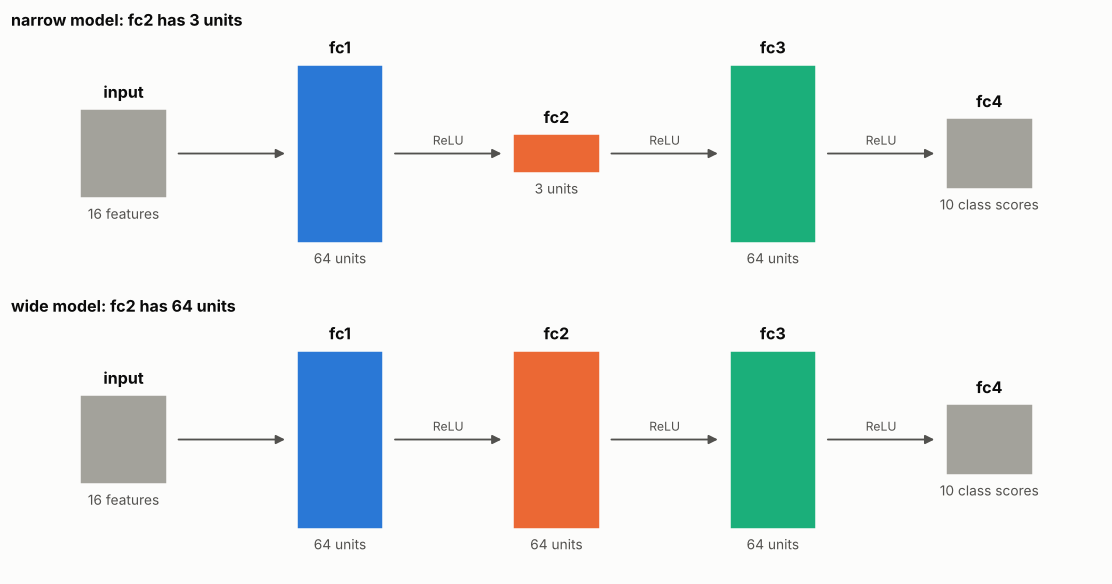

,fc1,fc2,fc3,fc4
weights,,,,
narrow,1088,195,256,650
wide,1088,4160,4160,650


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2))
for ax, name in zip(axes, WIDTH):
    draw_architecture(ax, WIDTH[name], f"{name} model: fc2 has {WIDTH[name]} units")
plt.show()
display(pd.DataFrame({name: {layer: sum(p.numel() for p in Student(w).get_submodule(layer).parameters())
                             for layer in LAYERS + ["fc4"]} for name, w in WIDTH.items()}).T.rename_axis("weights"))

## 3. Training

```python
for model in [narrow, wide]:                   # the same recipe for both
    for epoch in 1..60:
        for x, y in batches of 128:
            loss = cross_entropy(model(x), y)
            loss.backward();  adam.step()
        checkpoints[model][epoch] = copy(model.weights)    # later sections compare checkpoints
```

Shaded windows: the "early" and "late" checkpoints used for the verdicts in §25.

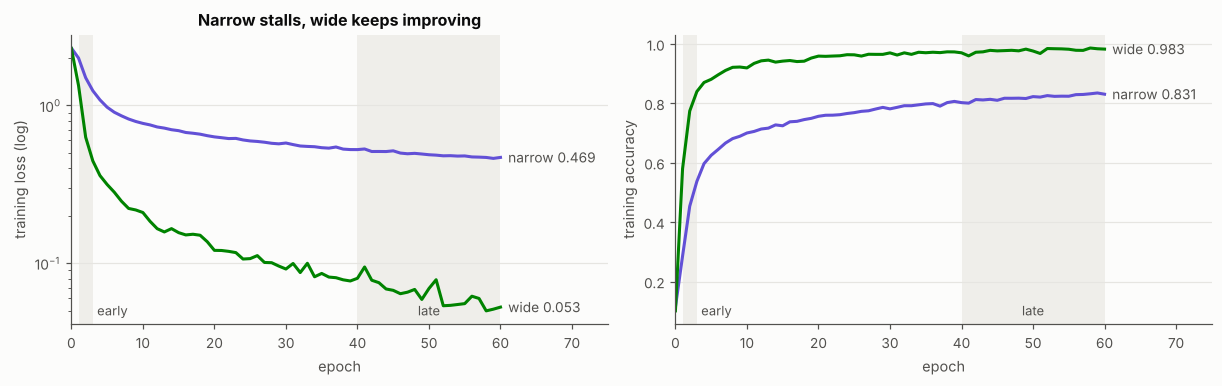

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name in WIDTH:
    h = HIST[name]
    for ax, col in zip(axes, ["loss", "acc"]):
        ax.plot(h.index, h[col], color=MODEL_COLOR[name])
        end_label(ax, h.index[-1], h[col].iloc[-1], f"{name} {h[col].iloc[-1]:.3f}")
for ax in axes:
    for lo, hi, text, x, ha in [(1, 3, "early", 3.6, "left"), (40, 60, "late", 50, "center")]:
        ax.axvspan(lo, hi, color=BAND, lw=0, zorder=0)
        ax.text(x, 0.03, text, transform=ax.get_xaxis_transform(), ha=ha, fontsize=8.5, color=INK2)
    ax.set_xlabel("epoch")
    ax.set_xlim(0, 75)
axes[0].set_yscale("log")
axes[0].set_ylabel("training loss (log)")
axes[1].set_ylabel("training accuracy")
axes[0].set_title("Narrow stalls, wide keeps improving")
plt.show()